# Hodgkin–Huxley Model: Computational Simulation of Neuronal Action Potentials

This project implements the Hodgkin–Huxley model to simulate the electrical activity of a neuron using Python.

The model describes how voltage-dependent sodium and potassium conductances interact to generate action potentials. By numerically solving a system of coupled differential equations, the simulation tracks membrane potential and ion-channel gating dynamics in response to external electrical stimulation.

The project investigates action potential generation, firing thresholds, all-or-none behavior, numerical stability, and the effects of ion-channel kinetics on neuronal excitability.

Forward Euler and explicit midpoint integration methods are implemented and compared to evaluate the numerical behavior of the system under different time-step conditions.

The analysis demonstrates how computational modeling can be used to investigate cellular electrophysiology and the mechanisms underlying neuronal signaling.

----
### Mathematical Model

The Hodgkin–Huxley model describes changes in neuronal membrane potential through the combined effects of sodium, potassium, and leak currents.

The membrane potential follows:

$$
C_m\frac{dV}{dt}=I_{\mathrm{ext}}-I_{\mathrm{Na}}-I_{\mathrm{K}}-I_{\mathrm{L}}
$$

where:

- $V$: Membrane potential (mV)
- $C_m$: Membrane capacitance
- $I_{\mathrm{ext}}$: Externally applied current
- $I_{\mathrm{Na}}$: Sodium current
- $I_{\mathrm{K}}$: Potassium current
- $I_{\mathrm{L}}$: Leak current

The ionic currents are defined as:

$$
I_{\mathrm{Na}}=g_{\mathrm{Na}}m^3h(V-E_{\mathrm{Na}})
$$

$$
I_{\mathrm{K}}=g_{\mathrm{K}}n^4(V-E_{\mathrm{K}})
$$

$$
I_{\mathrm{L}}=g_{\mathrm{L}}(V-E_{\mathrm{L}})
$$

The variables \(m\), \(h\), and \(n\) represent voltage-dependent gating states:

- $m$: Sodium activation
- $h$: Sodium inactivation
- $n$: Potassium activation

Each gating variable follows a first-order differential equation:

$$
\frac{dq}{dt}=\alpha_q(V)(1-q)-\beta_q(V)q
$$

where $q$ represents $m$, $h$, or $n$.

The voltage-dependent rate functions determine how rapidly each gating variable responds to changes in membrane potential.

Together, these equations describe the feedback mechanisms responsible for action potential initiation, repolarization, and recovery.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- constants (squid giant axon, Hodgkin & Huxley 1952) ----
C_M  = 1.0                      # membrane capacitance,  uF/cm^2
G_NA, E_NA = 120.0,  50.0       # sodium    conductance mS/cm^2, reversal mV
G_K,  E_K  =  36.0, -77.0       # potassium
G_L,  E_L  =   0.3, -54.387     # leak

# ---- the six empirical rate functions. GIVEN, and the only given code. ----
# Curve fits to voltage-clamp data, done by hand in 1952. No theory predicts
# them. Units: 1/ms, with V in mV.
def _safe(num, den, limit):
    """0/0 guard: alpha_m at V = -40 and alpha_n at V = -55 are removable."""
    return limit if abs(den) < 1e-9 else num / den

def alpha_m(V): return _safe(0.1*(V+40.0), 1.0-np.exp(-(V+40.0)/10.0), 1.0)
def beta_m(V):  return 4.0*np.exp(-(V+65.0)/18.0)
def alpha_h(V): return 0.07*np.exp(-(V+65.0)/20.0)
def beta_h(V):  return 1.0/(1.0+np.exp(-(V+35.0)/10.0))
def alpha_n(V): return _safe(0.01*(V+55.0), 1.0-np.exp(-(V+55.0)/10.0), 0.1)
def beta_n(V):  return 0.125*np.exp(-(V+65.0)/80.0)

def steady(a, b):
    """For a gate with opening rate a and closing rate b, return (x_inf, tau)."""
    return a/(a+b), 1.0/(a+b)

def rest_state():
    """The cell at -65 mV with every gate sitting at its steady value."""
    V = -65.0
    m, _ = steady(alpha_m(V), beta_m(V))
    h, _ = steady(alpha_h(V), beta_h(V))
    n, _ = steady(alpha_n(V), beta_n(V))
    return V, m, h, n

V0, m0, h0, n0 = rest_state()
print(f"rest:  V = {V0:.1f} mV   m = {m0:.3f}   h = {h0:.3f}   n = {n0:.3f}")
for lab, a, b in [("m", alpha_m, beta_m), ("h", alpha_h, beta_h), ("n", alpha_n, beta_n)]:
    _, tau = steady(a(V0), b(V0))
    print(f"  tau_{lab} at rest = {tau:5.2f} ms")

rest:  V = -65.0 mV   m = 0.053   h = 0.596   n = 0.318
  tau_m at rest =  0.24 ms
  tau_h at rest =  8.52 ms
  tau_n at rest =  5.46 ms


### Numerical Implementation: Hodgkin–Huxley Differential Equations

The Hodgkin–Huxley model is implemented as a system of four coupled ordinary differential equations describing membrane potential and ion-channel gating dynamics.

The `derivatives()` function calculates the instantaneous rates of change of membrane potential (`V`) and the three gating variables (`m`, `h`, and `n`).

Sodium, potassium, and leak currents are calculated using their respective conductances and electrochemical driving forces, defined by the difference between membrane potential and each ion's reversal potential.

The membrane potential derivative is determined by the balance between externally applied current and the three ionic currents. The gating variable derivatives are calculated using voltage-dependent activation and inactivation rate functions.

Separating the differential equations from the numerical integration algorithm allows the same model to be evaluated using different numerical methods.

In [ ]:
def derivatives(V, m, h, n, I_ext):
    """F(X): the four time derivatives, given the state and the stimulus.

    Returns (dV, dm, dh, dn).  Nothing about time stepping belongs in here.
    """
    # the three ionic currents.  Driving force is (V - E), not V.
    i_na = G_NA * m**3 * h * (V - E_NA)
    i_k  = G_K * n**4 * (V - E_K)
    i_l  = G_L * (V - E_L)

    # the voltage equation. Outward ionic currents decrease membrane potential.
    dV = I_ext - i_na - i_k - i_l

    # the three gate equations, all with the same shape
    dm = alpha_m(V) * (1 - m) - (beta_m(V) * m)
    dh = alpha_h(V) * (1 - h) - (beta_h(V) * h)
    dn = alpha_n(V) * (1 - n) - (beta_n(V) * n)
    return dV, dm, dh, dn


# --- check: at rest with no stimulus, nothing should be moving ---
dV, dm, dh, dn = derivatives(V0, m0, h0, n0, 0.0)
print(f"at rest:  dV/dt = {dV:+.5f} mV/ms")
print(f"          dm/dt = {dm:+.2e}   dh/dt = {dh:+.2e}   dn/dt = {dn:+.2e}")
print("the cell is sitting still" if abs(dV) < 0.01 else "something is moving")

at rest:  dV/dt = +0.00422 mV/ms
          dm/dt = +0.00e+00   dh/dt = +0.00e+00   dn/dt = +0.00e+00
the cell is sitting still


### Numerical Integration: Forward Euler Method

The coupled Hodgkin–Huxley differential equations are solved numerically using the forward Euler method.

At each time step, the method evaluates the derivatives of the current system state and updates membrane potential and gating variables using the selected time-step size (`dt`).

The implementation consists of three components:

- `euler_step()` performs a single numerical integration step and accepts a derivative function as an argument.
- `pulse()` generates a time-dependent external current stimulus with a specified amplitude, onset time, and duration.
- `run_hh()` simulates the neuron over a specified duration, storing membrane potential and gating-variable trajectories.

The simulation begins from the model's resting state and evaluates the external current at each numerical time step.

The modular implementation allows alternative integration methods to be substituted without rewriting the underlying Hodgkin–Huxley equations.

In [ ]:
def euler_step(V, m, h, n, I_ext, dt, F):
    """One Euler step: X <- X + dt * F(X)."""
    dV, dm, dh, dn = F(V, m, h, n, I_ext)

    V_new = V + dt * dV
    m_new = m + dt * dm
    h_new = h + dt * dh
    n_new = n + dt * dn

    return V_new, m_new, h_new, n_new


def pulse(amp, t0=5.0, dur=0.5):
    """Return a function giving amp during the stimulus window."""
    def I(t):
        if t >= t0 and t <= t0 + dur:
            return amp
        else:
            return 0.0
    return I


def run_hh(I_of_t, T=25.0, dt=0.01, step=euler_step, F=None):
    """Integrate the HH model from rest."""

    if F is None:
        F = derivatives

    V, m, h, n = rest_state()

    ts = [0.0]
    Vs = [V]
    ms = [m]
    hs = [h]
    ns = [n]

    for k in range(int(T / dt)):
        t_now = k * dt
        I_now = I_of_t(t_now)

        V, m, h, n = step(V, m, h, n, I_now, dt, F)

        ts.append((k + 1) * dt)
        Vs.append(V)
        ms.append(m)
        hs.append(h)
        ns.append(n)

    return (np.array(ts), np.array(Vs), np.array(ms), np.array(hs), np.array(ns))

t, V, m, h, n = run_hh(pulse(0.0), T=10.0, dt=0.01)


# --- check: with no stimulus at all, the cell should still be at rest ---
# (a pulse of zero amplitude, which also checks that pulse returns a function)
t, V, m, h, n = run_hh(pulse(0.0), T=10.0, dt=0.01)
print(f"{len(t)} samples, t runs 0 to {t[-1]:.2f} ms")
print(f"V drifted by {V[-1]-V[0]:+.4f} mV over 10 ms of doing nothing")

1001 samples, t runs 0 to 10.00 ms
V drifted by +0.0033 mV over 10 ms of doing nothing


### Action Potential Generation

The Hodgkin–Huxley model is simulated to investigate how a brief external electrical stimulus can initiate a neuronal action potential.

A current pulse with an amplitude of 20 µA/cm² is applied for 0.5 milliseconds, and membrane potential is simulated over 25 milliseconds using forward Euler integration with a time step of `dt = 0.01 ms`.

The resulting voltage trajectory illustrates the characteristic phases of an action potential, including rapid depolarization, repolarization, and afterhyperpolarization.

Although the external stimulus is brief, the resulting action potential continues after the stimulus ends. This behavior reflects the voltage-dependent feedback mechanisms underlying neuronal excitability.

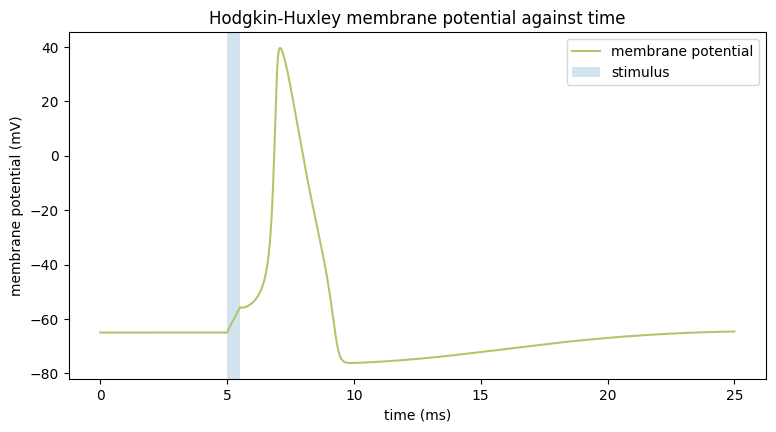

peak       : +39.6 mV
undershoot : -76.2 mV


In [ ]:
t, V, m, h, n = run_hh(pulse(20.0), T=25.0, dt=0.01)

plt.figure(figsize=(9, 4.5))
plt.plot(t, V, label="membrane potential", color="#B5C46A")
plt.axvspan(5.0, 5.5, alpha=0.2, label="stimulus")
plt.xlabel("time (ms)")
plt.ylabel("membrane potential (mV)")
plt.title("Hodgkin-Huxley membrane potential against time")
plt.legend()
plt.show()

print(f"peak       : {V.max():+.1f} mV")
print(f"undershoot : {V[np.argmax(V):].min():+.1f} mV")

### Voltage-Dependent Ion-Channel Gating Dynamics

To investigate the mechanisms underlying action potential generation, the membrane potential and three gating variables are plotted against time.

The gating variables represent distinct aspects of ion-channel behavior:

- **Sodium activation (`m`):** Increases rapidly during depolarization, promoting sodium influx and further membrane depolarization.
- **Sodium inactivation (`h`):** Decreases during sustained depolarization, reducing sodium conductance and helping terminate the rising phase of the action potential.
- **Potassium activation (`n`):** Increases more gradually, promoting outward potassium current that contributes to repolarization and afterhyperpolarization.

The relative timing of these gating processes is essential for generating the characteristic shape of an action potential.

Rapid sodium activation provides positive feedback during the initial depolarization, while sodium inactivation and delayed potassium activation contribute to recovery of the membrane potential.

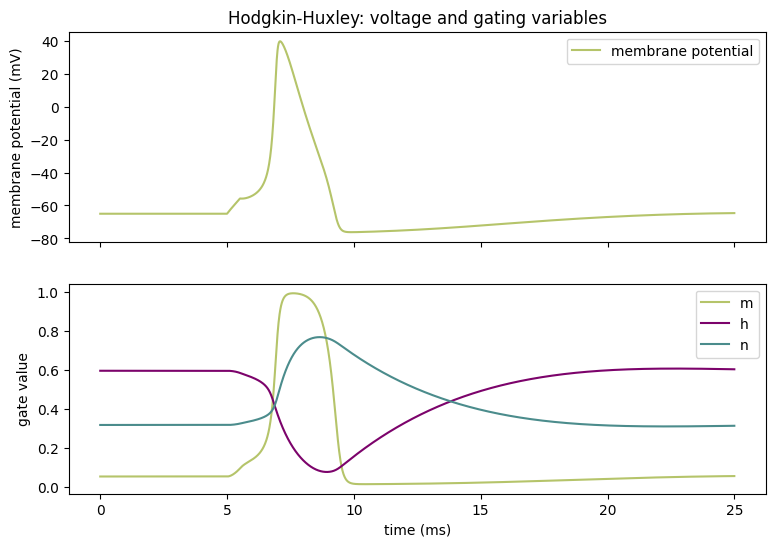

In [ ]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

a1.plot(t, V, label="membrane potential", color="#B5C46A")
a1.set_ylabel("membrane potential (mV)")
a1.set_title("Hodgkin-Huxley: voltage and gating variables")
a1.legend()

a2.plot(t, m, label="m", color="#B5C46A")
a2.plot(t, h, label="h", color="#7C036B")
a2.plot(t, n, label="n", color="#4B8C8C")
a2.set_xlabel("time (ms)")
a2.set_ylabel("gate value")
a2.legend()

plt.show()

### Ionic Conductances and Membrane Potential

The membrane potential is determined by the combined effects of sodium, potassium, and leak currents.

To investigate their relative contributions, the voltage-dependent sodium and potassium conductances are calculated from the simulated gating variables:

$$
g_{\mathrm{Na}}=G_{\mathrm{Na}}m^3h
$$

$$
g_{\mathrm{K}}=G_{\mathrm{K}}n^4
$$

The conductance-weighted reversal potential is then calculated as:

$$
V_{\mathrm{weighted}}=
\frac{g_{\mathrm{Na}}E_{\mathrm{Na}}+g_{\mathrm{K}}E_{\mathrm{K}}+G_{\mathrm{L}}E_{\mathrm{L}}}
{g_{\mathrm{Na}}+g_{\mathrm{K}}+G_{\mathrm{L}}}
$$

This quantity represents the membrane potential at which the net ionic current would be zero for the instantaneous conductance values.

The calculated value is compared with the simulated membrane potential at selected points during the action potential to investigate how changes in relative ionic conductances influence neuronal electrical activity.

In [ ]:
# The conductances are not constants: g_Na = G_NA * m**3 * h and g_K = G_K * n**4,
# both of which are arrays, because m, h and n are arrays.

g_na = G_NA * m**3 * h
g_k  = G_K * n**4
weighted = (g_na * E_NA + g_k * E_K + G_L * E_L) / (g_na + g_k + G_L)

i_rest  = 0
i_peak  = int(np.argmax(V))
i_under = i_peak + int(np.argmin(V[i_peak:]))

for label, i in [("rest", i_rest), ("peak", i_peak), ("undershoot", i_under)]:
    print(f"{label:11s} g_Na={g_na[i]:7.3f}  g_K={g_k[i]:6.3f}   "
          f"V={V[i]:+7.2f}   weighted average={weighted[i]:+7.2f}")

rest        g_Na=  0.011  g_K= 0.367   V= -65.00   weighted average= -64.99
peak        g_Na= 29.809  g_K= 2.425   V= +39.64   weighted average= +39.57
undershoot  g_Na=  0.000  g_K= 8.055   V= -76.19   weighted average= -76.19


### Results and Interpretation

The conductance analysis demonstrates how changes in sodium and potassium permeability influence the membrane potential throughout an action potential.

During rapid depolarization, increased sodium conductance drives the membrane potential toward the sodium reversal potential.

As sodium channels inactivate and potassium conductance increases, the membrane potential shifts toward the potassium reversal potential, producing repolarization and the subsequent undershoot.

The conductance-weighted reversal potential provides a useful reference for interpreting the direction of ionic current. However, the simulated membrane potential does not necessarily equal this value at every instant because membrane capacitance allows a transient difference between the two.

The analysis highlights how the timing and relative magnitudes of ionic conductances contribute to the generation and termination of neuronal action potentials.

## Action Potential Threshold Analysis

To investigate the relationship between stimulus intensity and neuronal excitability, the Hodgkin–Huxley model is simulated using external current pulses of varying amplitudes.

An initial parameter sweep evaluates stimulus amplitudes ranging from 0 to 80 µA/cm², while maintaining a pulse duration of 0.5 ms.

Each simulation runs for 25 ms using a numerical time step of `dt = 0.001 ms`.

The maximum membrane potential reached during each simulation is recorded to distinguish subthreshold responses from regenerative action potentials.

After identifying the approximate transition region, a narrower stimulus range is examined to estimate the firing threshold more precisely.

This analysis demonstrates how voltage-dependent sodium-channel activation produces a sharp transition between small membrane responses and full action potentials.

In [ ]:
for amp in [0, 5, 10, 12, 13, 14, 15, 20, 40, 80]:
    t, V, m, h, n = run_hh(pulse(amp), T=25.0, dt=0.001)
    print(f"amp = {amp}\npeak V = {V.max():.4f} mV")


def spikes(amp):
    """True if this stimulus produces an action potential."""
    t, V, m, h, n = run_hh(pulse(amp), T=25.0, dt=0.001)
    return V.max() > 15.0

lo, hi = 13.0, 14.0        # lo does not spike, hi does

for _ in range(30):
  mid = (lo + hi) / 2
  if spikes(mid):
    hi = mid
  else:
    lo = mid

print(f"threshold is between {lo:.4f} and {hi:.4f} µA/cm²")

amp = 0
peak V = -64.9928 mV
amp = 5
peak V = -62.7696 mV
amp = 10
peak V = -60.5195 mV
amp = 12
peak V = -59.6105 mV
amp = 13
peak V = -58.1047 mV
amp = 14
peak V = 36.7895 mV
amp = 15
peak V = 37.7695 mV
amp = 20
peak V = 39.3517 mV
amp = 40
peak V = 40.7833 mV
amp = 80
peak V = 41.5827 mV
threshold is between 13.2390 and 13.2390 µA/cm²


## All-or-None Action Potential Generation

To investigate the all-or-none behavior of neuronal action potentials, the model is simulated using two closely spaced stimulus amplitudes:

- Subthreshold stimulus: 13.2356 µA/cm²
- Suprathreshold stimulus: 13.2621 µA/cm²

The two stimuli differ by approximately 0.2%, yet produce substantially different membrane potential responses.

The resulting voltage trajectories are plotted together to visualize the transition from a small subthreshold depolarization to a regenerative action potential.

This comparison illustrates how nonlinear feedback in voltage-dependent ion channels allows a small difference in stimulus intensity to produce a large difference in neuronal response.

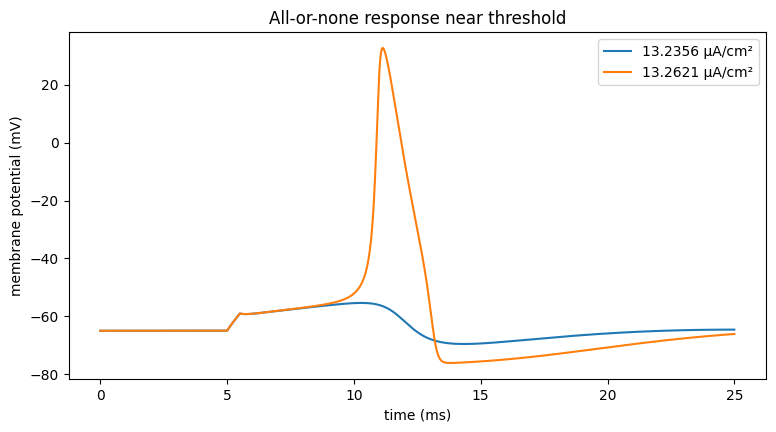

In [ ]:
amps = [13.2356, 13.2621]

plt.figure(figsize=(9, 4.5))
for amp in amps:
    t7, V7, m7, h7, n7 = run_hh(pulse(amp), T=25.0, dt=0.001, step=euler_step)
    plt.plot(t7, V7, label=f"{amp:.4f} µA/cm²")

plt.xlabel("time (ms)")
plt.ylabel("membrane potential (mV)")
plt.title("All-or-none response near threshold")
plt.legend()
plt.show()

### Results and Interpretation

The simulations demonstrate a sharp transition between subthreshold and suprathreshold neuronal responses.

At a stimulus amplitude of 13.2356 µA/cm², the membrane undergoes a relatively small depolarization and does not generate a full action potential.

Increasing the stimulus amplitude slightly to 13.2621 µA/cm² produces a regenerative action potential, with the peak membrane potential increasing from approximately −56 mV to +32 mV.

This large difference in response arises from the positive feedback between membrane depolarization and voltage-dependent sodium-channel activation.

Once sufficient depolarization occurs, sodium conductance increases rapidly, producing further depolarization and initiating the action potential.

Above threshold, increasing stimulus amplitude does not produce a proportional increase in action potential amplitude. Instead, the characteristic spike waveform is largely determined by the dynamics of the ion channels.

These findings demonstrate the nonlinear, all-or-none nature of neuronal excitation under the tested stimulation conditions.

### Numerical Integration: Explicit Midpoint Method

To investigate the effects of numerical integration on Hodgkin–Huxley simulations, a second-order explicit midpoint method is implemented as an alternative to forward Euler integration.

Unlike forward Euler, which estimates the next state using derivatives evaluated at the beginning of the time step, the midpoint method first estimates the state halfway through the interval. It then evaluates the derivatives at this intermediate state to calculate the full update.

For a system of differential equations,

$$
\frac{dX}{dt}=F(X),
$$

the explicit midpoint method calculates:

$$
X_{\mathrm{mid}}=X_t+\frac{dt}{2}F(X_t)
$$

$$
X_{t+dt}=X_t+dt\,F(X_{\mathrm{mid}})
$$

The `midpoint_step()` function uses the same interface as `euler_step()`, allowing both numerical methods to be evaluated through the existing `run_hh()` simulation function.

The midpoint method generally provides greater accuracy than forward Euler for sufficiently small time steps. However, higher accuracy does not guarantee numerical stability when the system contains rapidly changing dynamics.

In [ ]:
def midpoint_step(V, m, h, n, I_ext, dt, F):
    """Half a step to peek at the derivatives there, then the full step.

    Same signature as euler_step, so run_hh can take either one.
    """
    dV, dm, dh, dn = F(V, m, h, n, I_ext)

    V_half = V + 0.5 * dt * dV
    m_half = m + 0.5 * dt * dm
    h_half = h + 0.5 * dt * dh
    n_half = n + 0.5 * dt * dn

    dV_half, dm_half, dh_half, dn_half = F(V_half, m_half, h_half, n_half, I_ext)

    V_new = V + dt * dV_half
    m_new = m + dt * dm_half
    h_new = h + dt * dh_half
    n_new = n + dt * dn_half

    return V_new, m_new, h_new, n_new


# --- check: at a small step it should agree closely with Euler ---
_, Ve, *_ = run_hh(pulse(20.0), T=25.0, dt=0.001, step=euler_step)
_, Vm, *_ = run_hh(pulse(20.0), T=25.0, dt=0.001, step=midpoint_step)
print(f"peak with Euler    : {Ve.max():+.3f} mV")
print(f"peak with midpoint : {Vm.max():+.3f} mV")

peak with Euler    : +39.352 mV
peak with midpoint : +39.326 mV


## Numerical Stability Under Coarse Time Steps

The numerical stability of forward Euler and explicit midpoint integration is evaluated using a relatively large time step of `dt = 0.1 ms`.

Both methods simulate the same Hodgkin–Huxley system under an external current pulse of 20 µA/cm².

The simulation monitors the membrane potential trajectory and identifies when numerical values become non-finite.

This experiment investigates whether switching to a higher-order explicit integration method is sufficient to prevent instability during the rapid voltage changes associated with an action potential.

By comparing both methods under identical simulation conditions, the analysis distinguishes improvements in numerical accuracy from the separate requirement of numerical stability.

In [ ]:
np.seterr(all="warn")

for name, stepper in [("Euler", euler_step), ("midpoint", midpoint_step)]:
    t9, V9, m9, h9, n9 = run_hh(
        pulse(20.0), T=25.0, dt=0.1, step=stepper)

    finite = np.isfinite(V9)
    if np.all(finite):
        print(f"{name:8s}: all {len(V9)} voltage values remained finite")
    else:
        first_bad = np.flatnonzero(~finite)[0]
        print(f"{name:8s}: first non-finite V at t = {t9[first_bad]:.1f} ms\n{first_bad} of {len(V9)} samples were finite before it")

Euler   : first non-finite V at t = 8.0 ms
80 of 251 samples were finite before it
midpoint: first non-finite V at t = 7.4 ms
74 of 251 samples were finite before it


### Results: Numerical Instability

At a time step of `dt = 0.1 ms`, both forward Euler and explicit midpoint integration become numerically unstable during the action potential simulation.

The resulting membrane potential values eventually become non-finite, indicating that neither method successfully resolves the system's rapid dynamics at this time-step size.

Although the midpoint method has higher-order accuracy, both methods are explicit integrators and have stability limitations.

During an action potential, rapidly changing ionic conductances introduce short characteristic time scales. A numerical time step that is sufficiently small during resting conditions may therefore become too large during rapid depolarization.

These results demonstrate that selecting an appropriate integration method must be accompanied by an evaluation of the time scales governing the biological system.

### Membrane Time Constants and Numerical Stability

To investigate the source of numerical instability, the effective membrane time constant is calculated throughout an action potential.

The total instantaneous membrane conductance is defined as:

$$
g_{\mathrm{total}}=G_{\mathrm{Na}}m^3h+G_{\mathrm{K}}n^4+G_{\mathrm{L}}
$$

The corresponding membrane time constant is:

$$
\tau_m=\frac{C_m}{g_{\mathrm{total}}}
$$

As ionic conductances increase during an action potential, the effective membrane time constant decreases, indicating that membrane voltage can respond more rapidly.

The model is simulated using the explicit midpoint method with `dt = 0.001 ms`, and the resulting time constant is plotted throughout the simulation.

For a simple linear voltage-relaxation equation, forward Euler requires approximately:

$$
dt<2\tau_m
$$

for numerical stability.

This relationship provides a useful estimate of the time-step restrictions imposed by membrane conductance. However, it is not a complete stability criterion for the coupled nonlinear Hodgkin–Huxley system.

The analysis illustrates why numerical simulations must account for the fastest relevant dynamics, even when those dynamics occur over a relatively short portion of the simulation.

at rest        g_total =   0.68   tau = 1.477 ms
at the peak    g_total =  35.75   tau = 0.0280 ms

so an explicit method needs dt < about 2*tau = 0.056 ms


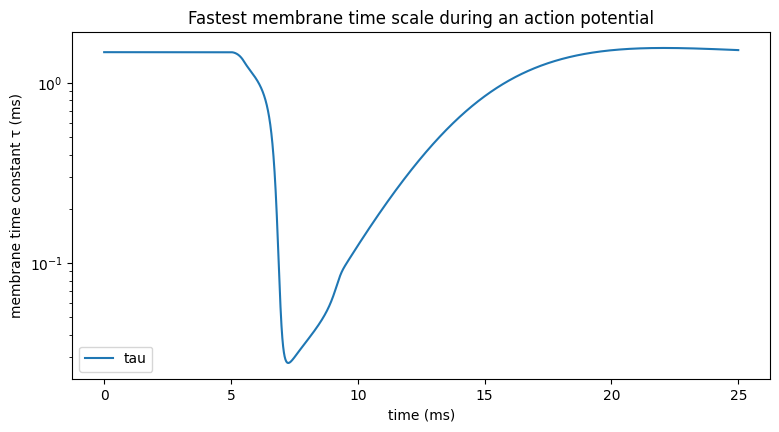

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

t, V, m, h, n = run_hh(pulse(20.0), T=25.0, dt=0.001, step=midpoint_step)

g_na = G_NA * m**3 * h
g_k  = G_K * n**4
g_total = g_na + g_k + G_L
tau = C_M/g_total

print(f"at rest        g_total = {g_total[0]:6.2f}   tau = {tau[0]:.3f} ms")
print(f"at the peak    g_total = {g_total.max():6.2f}   tau = {tau.min():.4f} ms")
print(f"\nso an explicit method needs dt < about 2*tau = {2*tau.min():.3f} ms")

plt.figure(figsize=(9, 4.5))
plt.plot(t, tau, label="tau")
plt.yscale("log")
plt.xlabel("time (ms)")
plt.ylabel("membrane time constant τ (ms)")
plt.title("Fastest membrane time scale during an action potential")
plt.legend()
plt.show()

### Interpretation: Fast Dynamics and Time-Step Selection

The membrane time constant varies substantially during an action potential because sodium and potassium conductances change dynamically.

During periods of elevated conductance, the membrane responds more rapidly to changes in ionic current. Consequently, numerical integration requires smaller time steps to resolve these fast transitions reliably.

The coarse-step simulations demonstrate that using a higher-order explicit method does not necessarily eliminate instability.

This behavior highlights the importance of evaluating characteristic time scales before selecting numerical integration parameters.

The coexistence of fast and slow dynamics can also create numerical challenges associated with stiffness, although a complete stiffness assessment requires examining the stability properties of the coupled differential equations.

Together, these experiments demonstrate the importance of numerical accuracy, stability, and time-step selection in computational electrophysiology.

### Sensitivity Analysis: Sodium Activation Kinetics

The Hodgkin–Huxley model depends on the relative timing of sodium activation, sodium inactivation, and potassium activation.

To investigate how sodium activation kinetics influence neuronal excitability, the sodium activation time constant is multiplied by a scaling factor `k`, while the steady-state activation function remains unchanged.

The modified sodium activation equation is:

$$
\frac{dm}{dt}=\frac{m_{\infty}(V)-m}{k\tau_m(V)}
$$

Increasing `k` slows the response of sodium activation to changes in membrane potential without directly modifying the maximum sodium conductance or sodium reversal potential.

A modified derivative function, `slow_m(k)`, is implemented to evaluate this change while preserving the remaining Hodgkin–Huxley equations.

The model is simulated using scaling factors of `(k=1,2,5,10,)` and `(20)`, with identical external stimulation and numerical integration settings.

A binary search is then used to estimate the critical scaling factor at which the simulated action potential no longer exceeds the selected peak-voltage criterion of +15 mV.

This experiment investigates whether rapid sodium activation is necessary to sustain the regenerative positive feedback responsible for action potential generation.

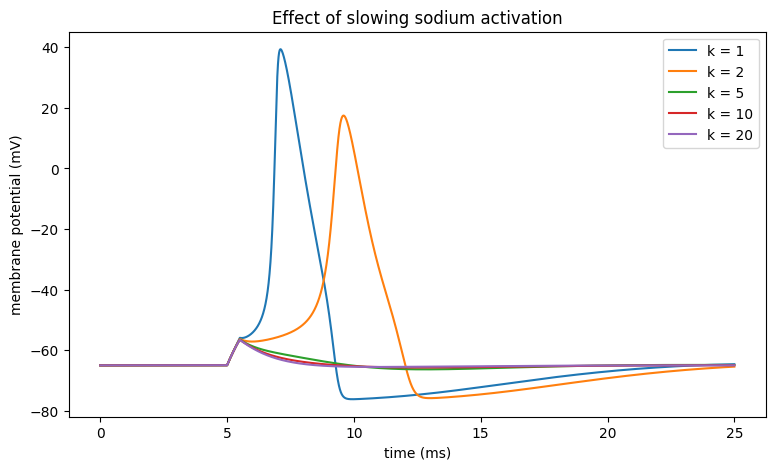

spike disappears at approximately k = 2.0553


In [ ]:
def slow_m(k):
    """Return a modified F in which tau_m is multiplied by k."""
    def F(V, m, h, n, I_ext):
        i_na = G_NA * m**3 * h * (V - E_NA)
        i_k = G_K * n**4 * (V - E_K)
        i_l = G_L * (V - E_L)

        dV = I_ext - i_na - i_k - i_l

        m_inf, tau_m = steady(alpha_m(V), beta_m(V))
        dm = (m_inf - m) / (k * tau_m)

        dh = alpha_h(V) * (1 - h) - beta_h(V) * h
        dn = alpha_n(V) * (1 - n) - beta_n(V) * n

        return dV, dm, dh, dn
    return F


plt.figure(figsize=(9, 5))
for k in [1, 2, 5, 10, 20]:
    tk, Vk, mk, hk, nk = run_hh(pulse(20.0), T=25.0, dt=0.001, step=midpoint_step, F=slow_m(k))
    plt.plot(tk, Vk, label=f"k = {k}")

plt.xlabel("time (ms)")
plt.ylabel("membrane potential (mV)")
plt.title("Effect of slowing sodium activation")
plt.legend()
plt.show()


def spike_with_k(k):
    tk, Vk, *_ = run_hh(pulse(20.0), T=25.0, dt=0.001, step=midpoint_step, F=slow_m(k))
    return Vk.max() > 15.0

lo, hi = 2.0, 5.0
for _ in range(25):
    mid = (lo + hi) / 2
    if spike_with_k(mid):
        lo = mid
    else:
        hi = mid

print(f"spike disappears at approximately k = {hi:.4f}")


### Results and Interpretation: Sodium Activation

The simulations demonstrate that action potential generation is sensitive to the rate of sodium-channel activation.

Increasing the scaling factor 'k' slows the activation variable 'm', delaying the increase in sodium conductance during membrane depolarization.

Although the maximum sodium conductance and reversal potential remain unchanged, slower activation weakens the rapid positive-feedback mechanism responsible for initiating an action potential.

As sodium activation becomes slower, competing potassium and leak currents can prevent the membrane from reaching the conditions necessary for regenerative excitation.

The binary-search analysis estimates the transition between spiking and non-spiking responses under the selected stimulus conditions.

These results demonstrate that neuronal excitability depends not only on the magnitude of ionic conductances but also on the relative time scales of ion-channel activation and inactivation.

### Parameter Calibration: Leak Reversal Potential and Resting Membrane Voltage

The leak reversal potential, $E_L$, influences the equilibrium membrane potential of the Hodgkin–Huxley model.

To investigate how this parameter is determined, the resting-state condition is applied at a membrane potential of −65 mV.

At equilibrium, the membrane potential does not change with time:

$$
\frac{dV}{dt}=0
$$

In the absence of external stimulation, the sodium, potassium, and leak currents must therefore sum to zero.

Rearranging the membrane voltage equation gives:

$$
E_L=V_{\mathrm{rest}}+
\frac{
g_{\mathrm{Na,rest}}(V_{\mathrm{rest}}-E_{\mathrm{Na}})
+g_{\mathrm{K,rest}}(V_{\mathrm{rest}}-E_{\mathrm{K}})
}{G_L}
$$

The calculated leak reversal potential is compared with the parameter value used in the original model.

To evaluate its influence on membrane equilibrium, the leak reversal potential is subsequently shifted by −5 mV and +5 mV.

For each modified parameter value, the system is simulated for 200 ms without external stimulation, allowing the membrane potential to approach a new resting state.

This analysis demonstrates how an experimentally constrained resting potential can be used to calibrate a model parameter and how changes in that parameter affect predicted membrane behavior.

In [ ]:
g_na_rest = G_NA * m0**3 * h0
g_k_rest  = G_K * n0**4
E_L_needed = V0 + (g_na_rest *(V0 - E_NA) + g_k_rest * (V0 - E_K))/G_L

print(f"E_L required for dV/dt = 0 at V = -65 : {E_L_needed:9.4f} mV")
print(f"E_L given in cell 1                   : {E_L:9.4f} mV")


def shifted_leak_F(delta):
    E_L_shifted = E_L + delta

    def F(V, m, h, n, I_ext):
        i_na = G_NA * m**3 * h * (V - E_NA)
        i_k = G_K * n**4 * (V - E_K)
        i_l = G_L * (V - E_L_shifted)

        dV = I_ext - i_na - i_k - i_l
        dm = alpha_m(V) * (1 - m) - beta_m(V) * m
        dh = alpha_h(V) * (1 - h) - beta_h(V) * h
        dn = alpha_n(V) * (1 - n) - beta_n(V) * n

        return dV, dm, dh, dn

    return F


for delta in [-5.0, +5.0]:
    tb, Vb, mb, hb, nb_ = run_hh(pulse(0.0), T=200.0, dt=0.01, step=midpoint_step, F=shifted_leak_F(delta))
    print(f"E_L shift {delta:+.1f} mV -> final resting voltage\nV = {Vb[-1]:+.3f} mV")

E_L required for dV/dt = 0 at V = -65 :  -54.4011 mV
E_L given in cell 1                   :  -54.3870 mV
E_L shift -5.0 mV -> final resting voltage
V = -66.436 mV
E_L shift +5.0 mV -> final resting voltage
V = -63.828 mV


### Results and Interpretation: Resting Potential Calibration

The leak reversal potential is calculated by imposing the experimentally observed resting membrane voltage of −65 mV as an equilibrium condition.

Unlike the sodium and potassium reversal potentials used in this exercise, the leak reversal potential is selected to ensure that the combined ionic currents balance at the specified resting voltage.

Consequently, the resting potential of −65 mV is not an independent prediction of this parameterization. Instead, it is an experimentally constrained input used to determine $E_L$.

Shifting the leak reversal potential by ±5 mV changes the equilibrium membrane voltage reached during simulations without external stimulation.

This demonstrates that the model's resting state depends on its parameterization.

The experiment also illustrates an important distinction in computational modeling: some parameters are independently measured, while others are calibrated to reproduce known experimental observations.

Recognizing this distinction is essential when evaluating which model outputs represent genuine predictions and which are consequences of the calibration process.